**Title:**
Detecting Defective Coffee by ATR-FTIR, Before and After Roasting

**Question:**
Can ATR-FTIR spectra distinguish between defective and defect-free coffee lots, and does that capability persist for roasted coffee?

**Data citation:**
Collazos-Escobar, G. A. et al., *Mid-infrared spectral dataset and
machine learning tools for defect detection in green and roasted coffee*,
Version 5, Mendeley Data (2026), https://doi.org/10.17632/dtd2fggpyp.5,
accessed 2026-11-05. License CC BY 4.0.

   ## Preprocessing
   Raw spectra can differ in overall intensity because of contact with the ATR crystal, the refractive index of the sample, and other instrument and session effects. Trimming to preserve only chemically relevant regions prevents CO2 and noise regions (1800 - 2800 cm⁻¹) from changing how the coffee bands are scaled when SNV is performed. SNV is applied to each spectrum so comparisons between spectra reflect band shapes. 

 ## Setup and imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

line_styles = ["-", "--"]          # one per defect status
hatches = [None, "///"]            # SD band fill, so classes differ without color

from scipy import stats


## Parameters

The 650 - 1800 cm⁻¹ region is preserved as it contains the fingerprint and carbonyl regions. The 1800 - 2800 cm⁻¹ region is trimmed as it contains information about triple bonds, which coffee essentially does not contain; this would mostly pick up atmospheric CO2. The 2800-3700 cm⁻¹ region is preserved as it contains key C-H and O-H stretches. Above 3700 cm⁻¹ the spectra are flat, so that region is also trimmed.

In [2]:
REGIONS = [(650, 1800),        # cm-1; fingerprint and carbonyl region
           (2800, 3700)]       # cm-1; C-H and O-H stretch region

CAFFEINE_WINDOW = (1654, 1659)                     # cm-1; caffeine C=O band, from <https://link.springer.com/article/10.1007/s002160050063, https://publisher.unimas.my/ojs/index.php/TUR/article/download/1137/681>; mean SNV over this window
CGA_WAVENUMBERS = [1725, 1687, 1640, 1289, 1114]   # cm-1; chlorogenic acid bands, from <https://pmc.ncbi.nlm.nih.gov/articles/PMC5855685/>; nearest measured point
ALPHA = 0.05                                       # significance level, after Holm correction over all bands and stages


## Loading
The following cell confirms that the raw data file matches its published description before plotting. It prints a summary of the file when it works. 

In [3]:
data = pd.read_excel("data/Dataset_Raw.xlsx")
# Wavenumber columns are numeric, label columns are not
def is_number(name):
    try:
        float(name)
        return True
    except ValueError:
        return False

wavenumbers = [c for c in data.columns if is_number(c)]
labels = [c for c in data.columns if c not in wavenumbers]

print(f"{len(data)} rows (one per coffee lot and processing stage)")
print("label columns:", labels)
print(f"{len(wavenumbers)} wavenumber columns, from {wavenumbers[0]} to {wavenumbers[-1]} cm-1")
print("measured variable: ATR-FTIR absorbance (AU)")
print("value range:", data[wavenumbers].min().min(), "to", data[wavenumbers].max().max())

100 rows (one per coffee lot and processing stage)
label columns: ['V1', 'Process', 'Defect status', 'Processing stage', 'Defect category', 'Within category ID', 'Coffee Lot ID']
900 wavenumber columns, from 648.556784 to 3999.433499 cm-1
measured variable: ATR-FTIR absorbance (AU)
value range: -0.013245 to 0.408103


## Limits of these data
- ATR can only see a few micrometers of each whole bean's surface
- While the dataset includes a defect category, there are only 25 defective lots in total, and so the 5 categories of defects are too small to test separately
- The band intensities can show that defective and defect-free beans differ, but not which compound caused the difference, since the bands overlap

## Separate spectra from labels
The following cell separates absorbance values from labels in the raw data spreadsheet. The absorbances get preprocessed, and the labels are used to group spectra for plotting. The cell prints nothing when it works. 

In [4]:
stage = data["Processing stage"].to_numpy() # Green or Roasted
status = data["Defect status"].to_numpy() # Defective or Defect-free
wn = np.array([float(c) for c in wavenumbers])          # cm-1
X_raw = data[wavenumbers].to_numpy()                     # absorbance, 100 x 900

## Descriptive statistics
The following cell summarizes the raw data before any preprocessing: group sizes by processing stage and defect status, how the defective lots split by defect category, and the raw absorbance of each spectrum (its maximum and its mean over all 900 wavenumbers, in AU) summarised per group. It also checks for missing values and counts negative absorbances. 

The cell should print 25 lots in each stage x defect-status group, three tables, and the loading-check lines when it works.

In [5]:
# Group sizes: processing stage x defect status
group_counts = pd.crosstab(data["Processing stage"], data["Defect status"],
                           margins=True, margins_name="total")
display(group_counts)

# How the lots split by defect category, per processing stage
category_counts = pd.crosstab(data["Defect category"].fillna("none listed"),
                              data["Processing stage"])
display(category_counts)

# Raw absorbance of each spectrum, summarised per group (before SNV)
spectrum_summary = pd.DataFrame({
    "stage": stage,
    "status": status,
    "max absorbance (AU)": X_raw.max(axis=1),     # strongest point of each spectrum
    "mean absorbance (AU)": X_raw.mean(axis=1),   # average over all 900 wavenumbers
})
absorbance_table = (spectrum_summary
                    .groupby(["stage", "status"])[["max absorbance (AU)", "mean absorbance (AU)"]]
                    .agg(["mean", "std", "min", "max"])
                    .round(3))
display(absorbance_table)

# Loading checks
print("missing values in the spectra:", int(np.isnan(X_raw).sum()))
print("missing values per label column:", data.drop(columns=wavenumbers).isna().sum().to_dict())
negative = X_raw < 0                              # absorbance below zero, AU
print(f"negative absorbances: {negative.sum()} values in {negative.any(axis=1).sum()} of {len(X_raw)} spectra, "
      f"lowest {X_raw.min():.4f} AU at {wn[np.unravel_index(X_raw.argmin(), X_raw.shape)[1]]:.1f} cm-1")


Defect status,Defect-free,Defective,total
Processing stage,,,
Green,25,25,50
Roasted,25,25,50
total,50,50,100


Processing stage,Green,Roasted
Defect category,,
Bitten,5,5
Black,5,5
Defect-free,25,25
Discolored,5,5
Drill bit,5,5
Vinegar,5,5


max absorbance (AU)                       \
                                   mean    std    min    max   
stage   status                                                 
Green   Defect-free               0.371  0.025  0.319  0.406   
        Defective                 0.361  0.022  0.311  0.408   
Roasted Defect-free               0.261  0.021  0.216  0.300   
        Defective                 0.303  0.018  0.246  0.331   

                    mean absorbance (AU)                       
                                    mean    std    min    max  
stage   status                                                 
Green   Defect-free                0.093  0.009  0.077  0.104  
        Defective                  0.082  0.008  0.068  0.096  
Roasted Defect-free                0.063  0.004  0.053  0.070  
        Defective                  0.074  0.004  0.064  0.080

missing values in the spectra: 0
missing values per label column: {'V1': 0, 'Process': 0, 'Defect status': 0, 'Processing stage': 0, 'Defect category': 0, 'Within category ID': 0, 'Coffee Lot ID': 0}
negative absorbances: 2484 values in 24 of 100 spectra, lowest -0.0132 AU at 2161.9 cm-1


In each processing stage, there are 25 defect-free lots, and 5 lots in each of the five defect categories: bitten, black, discolored, drill bit, and vinegar, resulting in 50 lots per stage and 100 lots in total.

## Untrimmed SNV
The following cell creates untrimmed SNV plots that help to justify the decision for trimming, and the decision for no derivative. SNV is applied to the full range, class means +- 1 SD per processing stage, shading the trimmed regions. 

The goal is to show that the trimmed regions carry no coffee bands, and that band-free regions overlap after SNV (no remaining offset or tilt). 

The y-values differ slightly from the trimmed plot because SNV includes the excluded regions in each spectrum's mean and SD.

When the cell works, it will generate two panels, green and roasted, each with solid and a dashed mean.

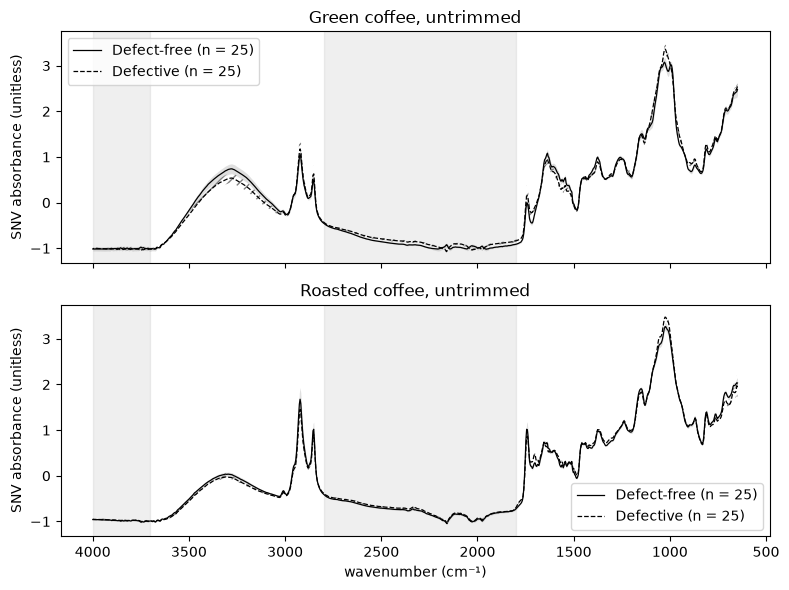

In [6]:
# SNV on the full, untrimmed spectra (evidence only, not the analysis pipeline)
X_snv_untrimmed = ((X_raw - X_raw.mean(axis=1, keepdims=True))
                   / X_raw.std(axis=1, keepdims=True))         # unitless, 100 x 900

# Regions excluded by REGIONS: the gap between the two kept regions, and above the upper one
excluded = [(REGIONS[0][1], REGIONS[1][0]),                    # cm-1; 1800-2800
            (REGIONS[1][1], wn.max())]                         # cm-1; 3700-3999

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True)
for ax, stage_name in zip(axes, ["Green", "Roasted"]):
    for status_value, ls, hatch in zip(np.unique(status), line_styles, hatches):
        rows = (stage == stage_name) & (status == status_value)  # the 25 lots in this stage and defect status
        mean = X_snv_untrimmed[rows].mean(axis=0)                # unitless, per wavenumber
        sd = X_snv_untrimmed[rows].std(axis=0)                   # unitless, per wavenumber
        # solid grey band for one class, hatched outline for the other, so classes differ without color
        if hatch is None:
            ax.fill_between(wn, mean - sd, mean + sd, color="grey", alpha=0.25, lw=0)
        else:
            ax.fill_between(wn, mean - sd, mean + sd, facecolor="none",
                            edgecolor="grey", hatch=hatch, lw=0)
        ax.plot(wn, mean, ls=ls, lw=0.9, color="black",
                label=f"{status_value} (n = {rows.sum()})")
    for low, high in excluded:
        ax.axvspan(low, high, color="grey", alpha=0.12)          # region excluded from analysis
    ax.set_title(f"{stage_name} coffee, untrimmed")
    ax.set_ylabel("SNV absorbance (unitless)")
    ax.legend()
axes[1].set_xlabel("wavenumber (cm⁻¹)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()


Apart from the small CO2 peak near 2350 cm⁻¹, the shaded regions are flat and are relatively band-free, sitting at about -1 SNV. The solid and dashed means overlap in the roasted coffee plot, but have more separation in the green coffee plot between 2800 - 1800 cm⁻¹. However, this is not a uniform offset, could be created by the SNV itself, and is in a band-free region regardless, so there is no need for a derivative. 

## SNV preprocessing and class means
Each trimmed spectrum is centred on its own mean and divided by its own standard deviation (SNV), removing offset and multiplicative differences from sample contact with crystal. Expected output: the array shapes, and the mean SNV spectrum ± 1 SD for each defect status, one panel per processing stage.


raw: (100, 900)  trimmed: (100, 549)  SNV: (100, 549)


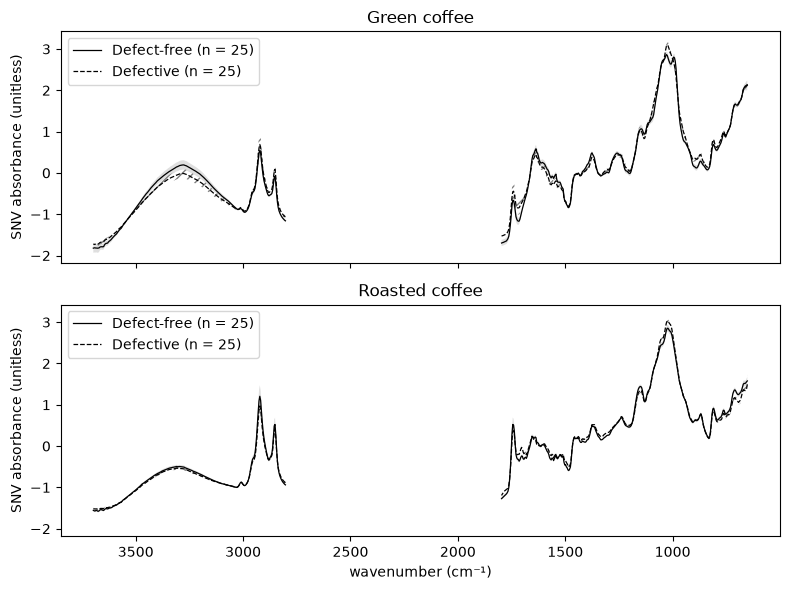

In [7]:
# 1. Trim to the kept regions
keep_snv = np.zeros(wn.shape, dtype=bool)
for low, high in REGIONS:
    keep_snv |= (wn >= low) & (wn <= high)
X_kept = X_raw[:, keep_snv]                                   # absorbance (AU)

# 2. SNV on each spectrum
X_snv_only = ((X_kept - X_kept.mean(axis=1, keepdims=True))
              / X_kept.std(axis=1, keepdims=True))            # unitless

print("raw:", X_raw.shape, " trimmed:", X_kept.shape, " SNV:", X_snv_only.shape)

# Back onto the full grid with NaN in the removed regions, so the plot shows a gap
X_snv_only_full = np.full(X_raw.shape, np.nan)
X_snv_only_full[:, keep_snv] = X_snv_only

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True)
for ax, stage_name in zip(axes, ["Green", "Roasted"]):
    for status_value, ls, hatch in zip(np.unique(status), line_styles, hatches):
        rows = (stage == stage_name) & (status == status_value) # Selects the 25 lots in this stage and defect status
        mean = X_snv_only_full[rows].mean(axis=0) # Per-wavenumber values in unitless SNV units
        sd = X_snv_only_full[rows].std(axis=0) # Per-wavenumber values in unitless SNV units
        # solid grey band for one class, hatched outline for the other, so classes differ without color
        if hatch is None:
            ax.fill_between(wn, mean - sd, mean + sd, color="grey", alpha=0.25, lw=0)
        else:
            ax.fill_between(wn, mean - sd, mean + sd, facecolor="none",
                            edgecolor="grey", hatch=hatch, lw=0)
        ax.plot(wn, mean, ls=ls, lw=0.9, color="black",
                label=f"{status_value} (n = {rows.sum()})")
    ax.set_title(f"{stage_name} coffee")
    ax.set_ylabel("SNV absorbance (unitless)")
    ax.legend()
axes[1].set_xlabel("wavenumber (cm⁻¹)")
axes[1].invert_xaxis()
plt.tight_layout()
plt.show()


The top plot shows the spectra of the defect-free and defective green coffee beans across the 3700 - 2800 cm^-1 and 1800 - 650 cm^-1 regions. The bottom plot shows the spectra of the defect-free and defective roasted coffee beans across the 3700 - 2800 cm^-1 and 1800 - 650 cm^-1 regions. 

## What exploration changed
- Untrimmed SNV plots showed that the 4000 - 3700 cm^-1 and 2800 - 1800 cm^-1 regions were flat, and with no coffee bands apart from the CO2 band near 2350 cm^-1. The analysis keeps 3700 - 2800 cm^_1 and 1800 - 650 cm^-1, stopping CO2 and noise from affecting each spectrum's SNV mean and SD
- After SNV, the band-free regions overlap near -1 SNV in both processing stages, and the only gap is in the green bean plot between 2800 and 1800 cm^-1, but it is not a uniform offset and lies in an excluded region. The analysis keeps SNV only, but the derivative's band-sharpening role is not tested. 
- Defective green lots have a weaker O-H band near 3300 cm^-1, and water bending at about 1640 cm^-1 overlaps the caffeine window (1654 - 1659 cm^-1). However, the characterization file showed that moisture content overlapped between defective and defect-free coffee in both processing stages. Thus, differences near 1650 cm^-1 should not be attributed to water, though the weaker 3300 cm^-1 band is yet to be explored. 

## Band values for the two-tailed test
The following cell extracts one value per spectrum for each band from the trimmed SNV spectra: the mean over the caffeine window, and the value at the measured point nearest each chlorogenic acid wavenumber. Bands were chosen from the literature before testing (see task 005). Expected output: a table listing each band and the measured wavenumbers used, which should lie within about 2 cm⁻¹ of each target.


In [8]:
wn_kept = wn[keep_snv]                       # cm-1; the 549 wavenumbers matching the columns of X_snv_only

band_values = {}                             # band name -> SNV value per spectrum (unitless, 100 values)
band_rows = []                               # one row per band for the table

# Caffeine: mean SNV over the window
in_window = (wn_kept >= CAFFEINE_WINDOW[0]) & (wn_kept <= CAFFEINE_WINDOW[1])
assert in_window.any(), "no measured points fall inside CAFFEINE_WINDOW"
name = f"caffeine {CAFFEINE_WINDOW[0]}-{CAFFEINE_WINDOW[1]}"
band_values[name] = X_snv_only[:, in_window].mean(axis=1)
band_rows.append({"band": name, "compound": "caffeine",
                  "measured wavenumbers used (cm-1)": ", ".join(f"{w:.1f}" for w in wn_kept[in_window])})

# Chlorogenic acids: SNV value at the measured point nearest each target
for target in CGA_WAVENUMBERS:
    idx = np.argmin(np.abs(wn_kept - target))   # index of the nearest measured wavenumber
    name = f"CGA {target}"
    band_values[name] = X_snv_only[:, idx]
    band_rows.append({"band": name, "compound": "chlorogenic acid",
                      "measured wavenumbers used (cm-1)": f"{wn_kept[idx]:.1f}"})

band_table = pd.DataFrame(band_rows)
band_table


,band,compound,measured wavenumbers used (cm-1)
0,caffeine 1654-1659,caffeine,"1654.9, 1658.7"
1,CGA 1725,chlorogenic acid,1725.8
2,CGA 1687,chlorogenic acid,1688.5
3,CGA 1640,chlorogenic acid,1640.0
4,CGA 1289,chlorogenic acid,1289.7
5,CGA 1114,chlorogenic acid,1114.5


## Two-tailed Welch t-tests, defective vs defect-free, per processing stage
For each band and each stage, the following cell compares the 25 defective with the 25 defect-free lots using Welch's two-tailed t-test (independent lots, variances not assumed equal). p-values are Holm-corrected over all 12 tests. The table gives each group's mean, the difference (defective minus defect-free) with its 95% confidence interval, and Shapiro–Wilk p-values as a normality check; a Shapiro p below 0.05 means that group's values may not be normal, and a Mann–Whitney U test should be checked for that band. Expected output: a 12-row table.


In [9]:
rows = []
for stage_name in ["Green", "Roasted"]:
    for name, values in band_values.items():
        free = values[(stage == stage_name) & (status == "Defect-free")]           # SNV, unitless
        defective = values[(stage == stage_name) & (status == "Defective")]        # SNV, unitless
        assert len(free) == 25 and len(defective) == 25, f"unexpected group sizes for {stage_name}"

        result = stats.ttest_ind(defective, free, equal_var=False)   # Welch, two-sided by default
        ci = result.confidence_interval(confidence_level=0.95)       # CI of the mean difference
        rows.append({
            "stage": stage_name,
            "band": name,
            "mean defect-free": free.mean(),
            "mean defective": defective.mean(),
            "difference": defective.mean() - free.mean(),           # defective minus defect-free
            "95% CI low": ci.low,
            "95% CI high": ci.high,
            "t": result.statistic,
            "df": result.df,                                       # Welch degrees of freedom
            "p": result.pvalue,
            "Shapiro p defect-free": stats.shapiro(free).pvalue,
            "Shapiro p defective": stats.shapiro(defective).pvalue,
        })
results = pd.DataFrame(rows)

# Holm correction over all tests: sort p-values, scale the i-th smallest by (m - i),
# then carry the running maximum so adjusted p-values never decrease
m = len(results)
order = np.argsort(results["p"].to_numpy())
p_sorted = results["p"].to_numpy()[order]
holm_sorted = np.maximum.accumulate(np.minimum(1, (m - np.arange(m)) * p_sorted))
p_holm = np.empty(m)
p_holm[order] = holm_sorted
results["p (Holm)"] = p_holm
results["significant"] = results["p (Holm)"] < ALPHA

results.round(4)


,stage,band,mean defect-free,mean defective,difference,95% CI low,95% CI high,t,df,p,Shapiro p defect-free,Shapiro p defective,p (Holm),significant
0,Green,caffeine 1654-1659,0.2488,0.1881,-0.0607,-0.0932,-0.0282,-3.7691,42.3059,0.0005,0.7294,0.0734,0.0020,True
1,Green,CGA 1725,-1.1217,-0.8260,0.2957,0.2187,0.3727,7.7463,42.6373,0.0000,0.0322,0.2668,0.0000,True
2,Green,CGA 1687,-0.6578,-0.5569,0.1010,0.0709,0.1310,6.8856,27.3354,0.0000,0.5791,0.4931,0.0000,True
3,Green,CGA 1640,0.5505,0.4272,-0.1233,-0.1816,-0.0649,-4.2522,45.9801,0.0001,0.5231,0.1566,0.0005,True
4,Green,CGA 1289,0.1321,0.1397,0.0076,-0.0175,0.0328,0.6118,42.0188,0.5440,0.1553,0.2610,0.5440,False
5,Green,CGA 1114,1.2096,1.1647,-0.0449,-0.0756,-0.0142,-2.9413,46.7464,0.0051,0.4762,0.8589,0.0152,True
6,Roasted,caffeine 1654-1659,0.1790,0.2016,0.0226,-0.0020,0.0473,1.8448,46.7808,0.0714,0.0370,0.5463,0.1428,False
7,Roasted,CGA 1725,-0.2854,-0.2010,0.0844,0.0541,0.1147,5.6133,43.4300,0.0000,0.7057,0.5583,0.0000,True
8,Roasted,CGA 1687,-0.2823,-0.1619,0.1204,0.1030,0.1377,13.9555,46.4695,0.0000,0.9992,0.9997,0.0000,True
9,Roasted,CGA 1640,0.2198,0.1450,-0.0748,-0.0982,-0.0513,-6.4178,46.7886,0.0000,0.6958,0.2334,0.0000,True


For the green coffee beans, the difference between defective and defect-free spectra for the caffeine band is significant (defective − defect-free = −0.061 SNV units, 95% CI −0.093 to −0.028, Holm-corrected p = 0.002), and 4/5 of the chlorogenic acid bands are significant (Holm-corrected p ≤ 0.0152); the largest difference is at 1725 cm⁻¹ (+0.30, 95% CI 0.22 to 0.37), and the only non-significant band is 1289 cm⁻¹ (+0.008, Holm-corrected p = 0.54). 

For the roasted coffee beans, the difference for the caffeine band is not significant (+0.023, 95% CI −0.002 to 0.047, Holm-corrected p = 0.14), and 5/5 of the chlorogenic acid bands are significant (Holm-corrected p < 0.0001). Four chlorogenic acid bands (1725, 1687, 1640 and 1114 cm⁻¹) differ in the same direction in both stages, so that difference persists after roasting, while the caffeine difference does not.

An assumption to check next would be normality, since the two groups failed the Shapiro test (p = 0.032 and p = 0.037), which means that within each group, the 25 values are not roughly normally distributed. This can be checked by running Mann-Whitney U tests on the two bands, which doesn't assume a bell shape, and seeing if the conclusions change. 

**Software versions used to run this notebook**

In [10]:
import sys
from importlib.metadata import version

print("Python", sys.version.split()[0])
for package in ["pandas", "numpy", "scipy", "matplotlib", "openpyxl"]:
    print(package, version(package))


Python 3.14.7
pandas 3.0.6
numpy 2.5.3
scipy 1.18.1
matplotlib 3.11.2
openpyxl 3.1.5
